# NutriScan: AI-Powered Food Detection & Classification
### Capstone Project (CV) | Milestone 2: Image Classification - Base Model, Improvements and Final Model Selection

**Business context.** NutriScan lets a user photograph a meal and get its calories and macronutrients.
Milestone 1 located the food in each photo (zero-shot OWL-ViT detector), cropped it to 224x224 and
built a clean, leakage-free train / validation / test split across **17 food categories**.

**Goal of this milestone.** Build the model that *names* the dish in each crop:

1. A **base CNN** trained from scratch, to set a reference.
2. **Improvements**: augmentation, regularisation (BatchNorm, dropout, weight decay, label smoothing),
   architectural changes and **transfer learning** (MobileNetV2, EfficientNet-B0).
3. **Compare** all models on the validation set, **select** the best with a clear rationale, and
   evaluate it **once** on the untouched test set.
4. **Classify 2-3 test images** with the best model and interpret the result in business terms.

**Metrics.** Accuracy, **macro-F1** (every food counts equally, as decided in Milestone 1), and
**top-3 accuracy** (the app can show the user three suggestions to confirm with one tap).

## How to run
- **Google Colab:** Runtime > Change runtime type > **T4 GPU**, then Runtime > Run all.
  The notebook looks for the Milestone 1 output `NutriScan_M1/nutriscan_classification_dataset.zip`
  in your Google Drive. If it is not there, it builds an equivalent dataset from `Food_101.zip`
  (centre crop, stratified 70/15/15 split) so it always runs.
- **Local:** uses `outputs/classification_dataset/` produced by Milestone 1.
- Every setting is in the **Configuration** cell.

# 1. Setup

In [1]:
# Core libraries. Everything used here ships with Google Colab - no installs needed.
import os, sys, json, time, copy, random, shutil, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageOps
from IPython.display import display

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models
from torchvision.transforms import v2 as T

from sklearn.metrics import f1_score, accuracy_score, confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

warnings.filterwarnings("ignore")          # keep the submitted notebook clean
sns.set_style("whitegrid")
print(f"PyTorch {torch.__version__} | CUDA available: {torch.cuda.is_available()}")

PyTorch 2.14.1+cpu | CUDA available: False


## Configuration

In [2]:
IN_COLAB = "google.colab" in sys.modules
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

def seed_everything(seed=SEED):
    """Make every run reproducible (same split, same initial weights, same shuffles)."""
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
    if torch.cuda.is_available(): torch.cuda.manual_seed_all(seed)
seed_everything()

# ---- Paths ------------------------------------------------------------------
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    M1_ZIP   = Path("/content/drive/MyDrive/NutriScan_M1/nutriscan_classification_dataset.zip")
    RAW_ZIP  = Path("/content/drive/MyDrive/Food_101.zip")      # fallback source
    DATA_DIR = Path("/content/m2_data")
    OUT_DIR  = Path("/content/drive/MyDrive/NutriScan_M2")
else:
    M1_ZIP, RAW_ZIP = None, None
    DATA_DIR = Path.cwd() / "outputs" / "classification_dataset"   # Milestone 1 output
    OUT_DIR  = Path.cwd() / "outputs_m2"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---- Training settings --------------------------------------------------------
IMG_SIZE    = 160 if DEVICE == "cuda" else 96   # input resolution (smaller on a CPU-only machine to keep run time short)
BATCH_SIZE  = 32
NUM_WORKERS = 2 if IN_COLAB else 0
# Epochs per experiment (early stopping keeps the best epoch). A GPU (Colab) gets the full budget.
EPOCHS = ({"base_cnn": 15, "cnn_aug_reg": 25, "mobilenet_frozen": 8, "mobilenet_finetune": 8, "effnet_finetune": 8}
          if DEVICE == "cuda" else
          {"base_cnn": 6, "cnn_aug_reg": 8, "mobilenet_frozen": 3, "mobilenet_finetune": 3, "effnet_finetune": 3})
PATIENCE = 6               # early-stopping patience (epochs without val macro-F1 improvement)
FALLBACK_PER_CLASS = 300   # only used if the Milestone 1 dataset is not found on Colab
print("Device:", DEVICE, "| Data:", DATA_DIR, "| Outputs:", OUT_DIR)

Device: cpu | Data: /home/moti/Downloads/Food_101/NutriScan_Milestone1/outputs/classification_dataset | Outputs: /home/moti/Downloads/Food_101/NutriScan_Milestone1/outputs_m2


# 2. Loading the Milestone 1 dataset
The detected, cropped and split images from Milestone 1 are reused, so this milestone directly builds on
the earlier analysis. The split was made **before** any modelling and was checked for duplicate leakage.

In [3]:
def build_from_raw(raw_zip, out_dir, per_class=FALLBACK_PER_CLASS):
    """Fallback: create train/val/test folders from the raw Food_101.zip (centre crop, 70/15/15)."""
    raw_dir = Path("/content/food101_raw")
    if not any(raw_dir.rglob("*.jpg")):
        with zipfile.ZipFile(raw_zip) as z: z.extractall(raw_dir)
    files = [p for p in raw_dir.rglob("*.jp*g") if "__MACOSX" not in p.parts]
    df = pd.DataFrame({"path": files, "label": [p.parent.name for p in files]})
    df = df.sample(frac=1, random_state=SEED).groupby("label").head(per_class)
    tr, tmp = train_test_split(df, test_size=0.30, stratify=df.label, random_state=SEED)
    va, te = train_test_split(tmp, test_size=0.50, stratify=tmp.label, random_state=SEED)
    for split, d in [("train", tr), ("val", va), ("test", te)]:
        for p, lab in zip(d.path, d.label):
            dst = out_dir / split / lab; dst.mkdir(parents=True, exist_ok=True)
            im = ImageOps.fit(ImageOps.exif_transpose(Image.open(p)).convert("RGB"), (224, 224))
            im.save(dst / p.name, quality=92)

if IN_COLAB and not (DATA_DIR / "train").exists():
    if M1_ZIP.exists():
        with zipfile.ZipFile(M1_ZIP) as z: z.extractall(DATA_DIR)
        print("Extracted Milestone 1 dataset from Drive.")
    else:
        print("Milestone 1 zip not found - building the dataset from Food_101.zip ...")
        build_from_raw(RAW_ZIP, DATA_DIR)
assert (DATA_DIR / "train").exists(), f"Dataset not found in {DATA_DIR}"

CLASS_NAMES = sorted(p.name for p in (DATA_DIR / "train").iterdir() if p.is_dir())
CLS2IDX = {c: i for i, c in enumerate(CLASS_NAMES)}
N_CLASSES = len(CLASS_NAMES)

def list_split(split):
    """Return a dataframe of (path, label, y) for one split."""
    rows = [(p, p.parent.name) for p in sorted((DATA_DIR / split).rglob("*")) if p.suffix.lower() in {".jpg", ".jpeg", ".png"}]
    d = pd.DataFrame(rows, columns=["path", "label"]); d["y"] = d.label.map(CLS2IDX)
    return d

splits = {s: list_split(s) for s in ["train", "val", "test"]}
counts = pd.DataFrame({s: d.label.value_counts() for s, d in splits.items()}).loc[CLASS_NAMES]
print(f"{N_CLASSES} classes | " + " | ".join(f"{s}: {len(d)}" for s, d in splits.items()))
display(counts.T)

17 classes | train: 1189 | val: 255 | test: 256


label,apple_pie,chocolate_cake,donuts,falafel,french_fries,hot_dog,ice_cream,nachos,onion_rings,pancakes,pizza,ravioli,samosa,spring_rolls,strawberry_shortcake,tacos,waffles
train,70,70,70,70,70,70,69,70,70,70,70,70,70,70,70,70,70
val,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15,15
test,15,15,15,15,15,15,16,15,15,15,15,15,15,15,15,15,15


**Observations**
- 17 food classes with an identical class order in all three splits.
- The per-class counts are balanced in the working set, so plain cross-entropy is appropriate; **macro-F1**
  is still reported so that no single weak class can hide behind a good average.
- The test set is **held out**: it is used once, only for the final selected model.

## Pre-loading images into memory
The crops are small, so they are decoded once into a uint8 tensor. This removes JPEG decoding from every
epoch and makes training several times faster, especially on Colab where disk I/O is the bottleneck.

In [4]:
def load_tensor(paths, size=IMG_SIZE):
    """Decode, resize and stack images as a uint8 tensor of shape (N, 3, size, size)."""
    arr = np.stack([np.asarray(Image.open(p).convert("RGB").resize((size, size), Image.BILINEAR)) for p in paths])
    return torch.from_numpy(arr).permute(0, 3, 1, 2).contiguous()

t0 = time.time()
X = {s: load_tensor(d.path) for s, d in splits.items()}
Y = {s: torch.tensor(d.y.values) for s, d in splits.items()}
print(f"Loaded in {time.time() - t0:.0f}s:", {s: tuple(x.shape) for s, x in X.items()})

Loaded in 2s: {'train': (1189, 3, 96, 96), 'val': (255, 3, 96, 96), 'test': (256, 3, 96, 96)}


## Transforms: normalisation and augmentation
- **Evaluation transform:** convert to float and normalise with ImageNet statistics (Milestone 1 showed the
  dataset mean is close to ImageNet's, so the pretrained statistics are appropriate).
- **Training augmentation** (decided in Milestone 1 EDA): random resized crop, horizontal flip, small
  rotation, and brightness / contrast / saturation jitter to mimic real phone photos in poor light.

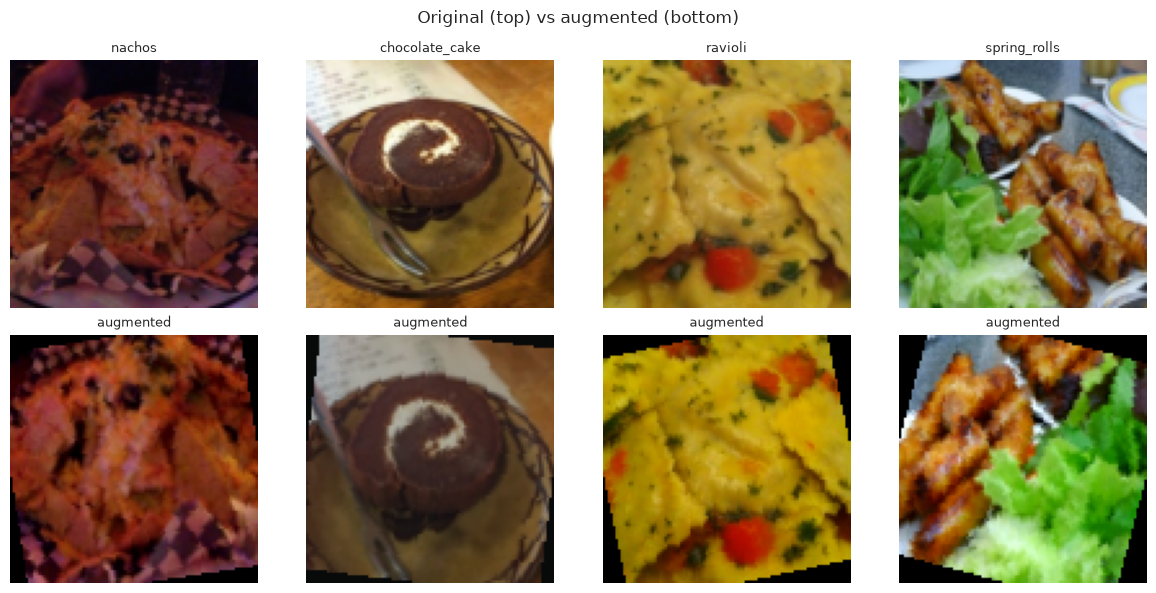

In [5]:
MEAN, STD = [0.485, 0.456, 0.406], [0.229, 0.224, 0.225]

eval_tf = T.Compose([T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])
aug_tf = T.Compose([
    T.RandomResizedCrop(IMG_SIZE, scale=(0.6, 1.0), antialias=True),
    T.RandomHorizontalFlip(),
    T.RandomRotation(15),
    T.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.3, hue=0.02),
    T.ToDtype(torch.float32, scale=True), T.Normalize(MEAN, STD)])

class TensorDS(Dataset):
    """Wraps pre-loaded uint8 images and applies a transform per sample."""
    def __init__(self, x, y, tf): self.x, self.y, self.tf = x, y, tf
    def __len__(self): return len(self.y)
    def __getitem__(self, i): return self.tf(self.x[i]), self.y[i]

def make_loader(split, augment=False):
    ds = TensorDS(X[split], Y[split], aug_tf if augment else eval_tf)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == "train"),
                      num_workers=NUM_WORKERS, pin_memory=(DEVICE == "cuda"))

# Visual check of what augmentation does to the same images
idx = np.random.default_rng(SEED).choice(len(Y["train"]), 4, replace=False)
fig, ax = plt.subplots(2, 4, figsize=(12, 6))
inv = lambda t: (t.permute(1, 2, 0).numpy() * STD + MEAN).clip(0, 1)
for j, i in enumerate(idx):
    ax[0, j].imshow(inv(eval_tf(X["train"][i]))); ax[0, j].set_title(CLASS_NAMES[Y["train"][i]], fontsize=9)
    ax[1, j].imshow(inv(aug_tf(X["train"][i]))); ax[1, j].set_title("augmented", fontsize=9)
for a in ax.flat: a.axis("off")
plt.suptitle("Original (top) vs augmented (bottom)"); plt.tight_layout()
plt.savefig(FIG_DIR / "m2_01_augmentation.png", dpi=150); plt.show()

# 3. Training and evaluation utilities
One shared training loop is used for every model so that the comparison is fair:
AdamW optimiser, cosine learning-rate schedule, model selection on **validation macro-F1**, early stopping.

In [6]:
@torch.no_grad()
def predict(model, split):
    """Return softmax probabilities and true labels for a split."""
    model.eval(); probs = []
    for xb, _ in make_loader(split):
        probs.append(F.softmax(model(xb.to(DEVICE)), dim=1).cpu())
    return torch.cat(probs).numpy(), Y[split].numpy()

def scores(probs, y):
    """Accuracy, macro-F1 and top-3 accuracy."""
    pred = probs.argmax(1)
    top3 = (np.argsort(-probs, 1)[:, :3] == y[:, None]).any(1).mean()
    return dict(acc=accuracy_score(y, pred), macro_f1=f1_score(y, pred, average="macro"), top3=top3)

def count_params(m):
    return sum(p.numel() for p in m.parameters()), sum(p.numel() for p in m.parameters() if p.requires_grad)

def train_model(name, model, epochs, lr, augment, weight_decay=0.0, label_smoothing=0.0, params=None):
    """Train with AdamW + cosine LR, keep the epoch with the best validation macro-F1."""
    seed_everything()
    model = model.to(DEVICE)
    opt = torch.optim.AdamW(params if params is not None else [p for p in model.parameters() if p.requires_grad],
                            lr=lr, weight_decay=weight_decay)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    crit = nn.CrossEntropyLoss(label_smoothing=label_smoothing)
    train_loader = make_loader("train", augment)
    hist, best, best_state, wait, t0 = [], -1, None, 0, time.time()
    for ep in range(1, epochs + 1):
        model.train(); tot, correct, n = 0.0, 0, 0
        for xb, yb in train_loader:
            xb, yb = xb.to(DEVICE), yb.to(DEVICE)
            opt.zero_grad(); out = model(xb); loss = crit(out, yb); loss.backward(); opt.step()
            tot += loss.item() * len(yb); correct += (out.argmax(1) == yb).sum().item(); n += len(yb)
        sched.step()
        pv, yv = predict(model, "val"); s = scores(pv, yv)
        val_loss = F.nll_loss(torch.log(torch.tensor(pv) + 1e-9), torch.tensor(yv)).item()
        hist.append(dict(epoch=ep, train_loss=tot / n, train_acc=correct / n, val_loss=val_loss, **{f"val_{k}": v for k, v in s.items()}))
        print(f"[{name}] ep {ep:2d} | train loss {tot/n:.3f} acc {correct/n:.3f} | val loss {val_loss:.3f} acc {s['acc']:.3f} F1 {s['macro_f1']:.3f}")
        if s["macro_f1"] > best:
            best, best_state, wait = s["macro_f1"], copy.deepcopy(model.state_dict()), 0
        else:
            wait += 1
            if wait >= PATIENCE: print(f"[{name}] early stop at epoch {ep}"); break
    model.load_state_dict(best_state)
    h = pd.DataFrame(hist); h.attrs["train_time_s"] = time.time() - t0
    return model, h

RESULTS, HISTORIES, MODELS = {}, {}, {}

def record(name, model, hist, description):
    """Store validation metrics, size, speed and the generalisation gap for the comparison table."""
    pv, yv = predict(model, "val"); s = scores(pv, yv)
    best = hist.loc[hist.val_macro_f1.idxmax()]
    total, trainable = count_params(model)
    model.eval(); x = torch.randn(1, 3, IMG_SIZE, IMG_SIZE).to(DEVICE)
    with torch.no_grad():
        for _ in range(3): model(x)
        t0 = time.time()
        for _ in range(20): model(x)
    RESULTS[name] = dict(description=description, val_acc=s["acc"], val_macro_f1=s["macro_f1"], val_top3=s["top3"],
                         train_acc=best.train_acc, gap=best.train_acc - s["acc"], best_epoch=int(best.epoch),
                         params_M=total / 1e6, trainable_M=trainable / 1e6, size_MB=total * 4 / 1e6,
                         latency_ms=(time.time() - t0) / 20 * 1000, train_time_s=hist.attrs["train_time_s"])
    HISTORIES[name], MODELS[name] = hist, model
    print({k: (round(v, 3) if isinstance(v, float) else v) for k, v in RESULTS[name].items()})

def plot_history(name):
    h = HISTORIES[name]; fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].plot(h.epoch, h.train_loss, label="train"); ax[0].plot(h.epoch, h.val_loss, label="val"); ax[0].set_title(f"{name}: loss")
    ax[1].plot(h.epoch, h.train_acc, label="train acc"); ax[1].plot(h.epoch, h.val_acc, label="val acc")
    ax[1].plot(h.epoch, h.val_macro_f1, label="val macro-F1", ls="--"); ax[1].set_title(f"{name}: accuracy")
    for a in ax: a.set_xlabel("epoch"); a.legend()
    plt.tight_layout(); plt.savefig(FIG_DIR / f"m2_curve_{name}.png", dpi=150); plt.show()

# 4. Model 1 - Base CNN (from scratch)
A simple, conventional CNN: three Conv-ReLU-MaxPool blocks followed by a fully connected classifier.
**No augmentation and no regularisation**, so it shows what a plain CNN can learn from ~1,200 training images.

[base_cnn] ep  1 | train loss 2.822 acc 0.071 | val loss 2.802 acc 0.078 F1 0.026


[base_cnn] ep  2 | train loss 2.729 acc 0.125 | val loss 2.749 acc 0.118 F1 0.068


[base_cnn] ep  3 | train loss 2.632 acc 0.168 | val loss 2.739 acc 0.114 F1 0.082


[base_cnn] ep  4 | train loss 2.517 acc 0.211 | val loss 2.752 acc 0.137 F1 0.110


[base_cnn] ep  5 | train loss 2.409 acc 0.246 | val loss 2.773 acc 0.145 F1 0.120


[base_cnn] ep  6 | train loss 2.332 acc 0.276 | val loss 2.753 acc 0.157 F1 0.139


{'description': 'Plain 3-block CNN, no augmentation / regularisation', 'val_acc': 0.157, 'val_macro_f1': 0.139, 'val_top3': np.float64(0.353), 'train_acc': np.float64(0.276), 'gap': np.float64(0.119), 'best_epoch': 6, 'params_M': 0.622, 'trainable_M': 0.622, 'size_MB': 2.489, 'latency_ms': 2.815, 'train_time_s': 75.535}


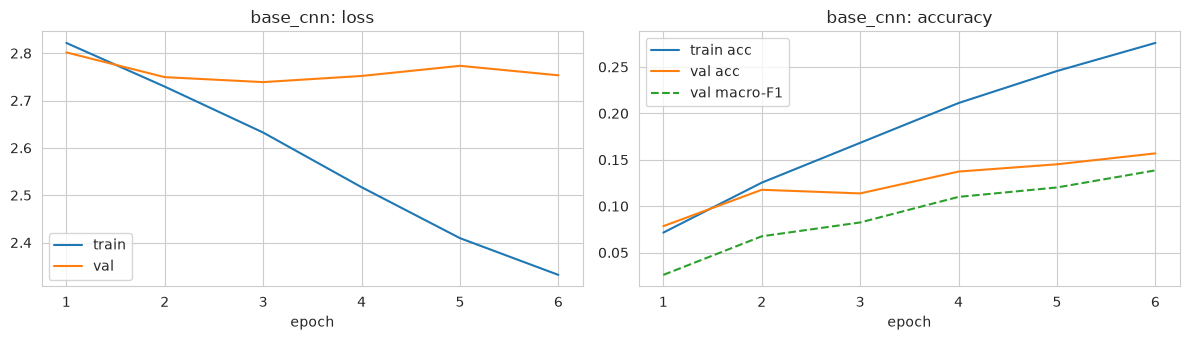

In [7]:
class BaseCNN(nn.Module):
    """3 conv blocks (32-64-128 filters) + dense head. Deliberately plain."""
    def __init__(self, n_classes):
        super().__init__()
        block = lambda i, o: nn.Sequential(nn.Conv2d(i, o, 3, padding=1), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, 32), block(32, 64), block(64, 128), nn.AdaptiveAvgPool2d(4))
        self.head = nn.Sequential(nn.Flatten(), nn.Linear(128 * 16, 256), nn.ReLU(), nn.Linear(256, n_classes))
    def forward(self, x): return self.head(self.features(x))

m, h = train_model("base_cnn", BaseCNN(N_CLASSES), EPOCHS["base_cnn"], lr=1e-3, augment=False)
record("base_cnn", m, h, "Plain 3-block CNN, no augmentation / regularisation")
plot_history("base_cnn")

In [8]:
# Observations for the base model, computed from its results
r = RESULTS["base_cnn"]
print(f"Base CNN: val accuracy {r['val_acc']:.1%}, macro-F1 {r['val_macro_f1']:.3f}, top-3 {r['val_top3']:.1%}")
print(f"Train accuracy at best epoch {r['train_acc']:.1%} -> generalisation gap {r['gap']:.1%}")
print(f"Random guessing would give {1/N_CLASSES:.1%}; the model is "
      f"{r['val_acc'] * N_CLASSES:.1f}x better than chance.")

Base CNN: val accuracy 15.7%, macro-F1 0.139, top-3 35.3%
Train accuracy at best epoch 27.6% -> generalisation gap 11.9%
Random guessing would give 5.9%; the model is 2.7x better than chance.


**Observations - base model**
- The plain CNN learns real signal (several times better than the 5.9% chance level), but its accuracy is far
  too low for a product: most meals would be logged wrongly.
- The training curve shows the classic **overfitting** pattern: training accuracy keeps rising while validation
  loss stops improving and then increases. With ~70 images per class the network memorises the training set
  instead of learning general food features.
- Conclusion: we need (a) more effective data via **augmentation**, (b) **regularisation**, and most of all
  (c) features learned from far more images - i.e. **transfer learning**.

# 5. Improving performance
## Model 2 - CNN + augmentation + regularisation + architectural changes
Changes versus the base model:
- **Architecture:** 4 conv blocks with two convolutions each, **Batch Normalisation**, and global average pooling
  instead of a large dense layer (far fewer parameters to overfit).
- **Regularisation:** dropout 0.4, weight decay 1e-4, label smoothing 0.1.
- **Augmentation:** the training transform from Section 2.

[cnn_aug_reg] ep  1 | train loss 2.881 acc 0.103 | val loss 2.795 acc 0.086 F1 0.051


[cnn_aug_reg] ep  2 | train loss 2.787 acc 0.113 | val loss 2.877 acc 0.075 F1 0.039


[cnn_aug_reg] ep  3 | train loss 2.758 acc 0.133 | val loss 2.840 acc 0.122 F1 0.103


[cnn_aug_reg] ep  4 | train loss 2.732 acc 0.128 | val loss 2.758 acc 0.137 F1 0.078


[cnn_aug_reg] ep  5 | train loss 2.687 acc 0.148 | val loss 2.708 acc 0.125 F1 0.078


[cnn_aug_reg] ep  6 | train loss 2.670 acc 0.162 | val loss 2.680 acc 0.125 F1 0.089


[cnn_aug_reg] ep  7 | train loss 2.648 acc 0.185 | val loss 2.681 acc 0.137 F1 0.094


[cnn_aug_reg] ep  8 | train loss 2.622 acc 0.178 | val loss 2.677 acc 0.149 F1 0.118


{'description': '4-block CNN + BatchNorm + dropout + weight decay + augmentation', 'val_acc': 0.149, 'val_macro_f1': 0.118, 'val_top3': np.float64(0.357), 'train_acc': np.float64(0.178), 'gap': np.float64(0.029), 'best_epoch': 8, 'params_M': 0.296, 'trainable_M': 0.296, 'size_MB': 1.185, 'latency_ms': 4.528, 'train_time_s': 141.611}


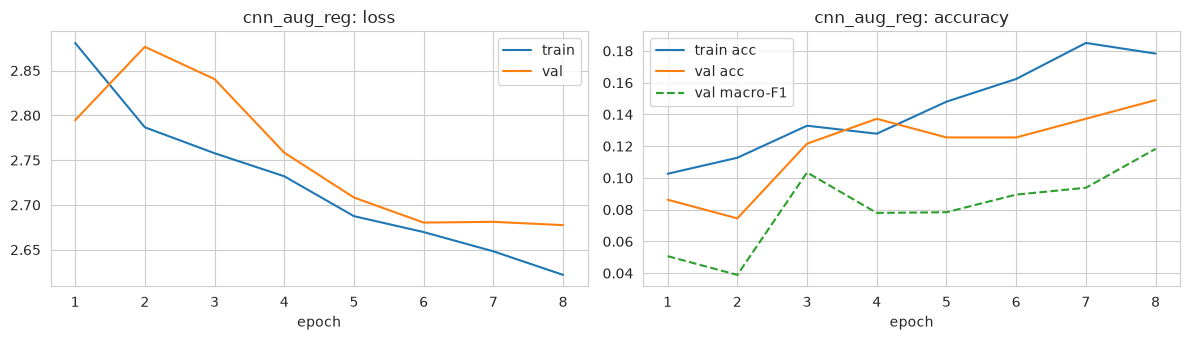

In [9]:
class ImprovedCNN(nn.Module):
    """4 double-conv blocks with BatchNorm, global average pooling and dropout."""
    def __init__(self, n_classes, p_drop=0.4, w=32):
        super().__init__()
        def block(i, o):
            return nn.Sequential(nn.Conv2d(i, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(),
                                 nn.Conv2d(o, o, 3, padding=1, bias=False), nn.BatchNorm2d(o), nn.ReLU(), nn.MaxPool2d(2))
        self.features = nn.Sequential(block(3, w), block(w, 2 * w), block(2 * w, 4 * w), block(4 * w, 8 * w), nn.AdaptiveAvgPool2d(1))
        self.head = nn.Sequential(nn.Flatten(), nn.Dropout(p_drop), nn.Linear(8 * w, n_classes))
    def forward(self, x): return self.head(self.features(x))

# Width 32 on a GPU; halved on CPU-only machines to keep training time reasonable.
m, h = train_model("cnn_aug_reg", ImprovedCNN(N_CLASSES, w=32 if DEVICE == "cuda" else 16), EPOCHS["cnn_aug_reg"], lr=2e-3, augment=True,
                   weight_decay=1e-4, label_smoothing=0.1)
record("cnn_aug_reg", m, h, "4-block CNN + BatchNorm + dropout + weight decay + augmentation")
plot_history("cnn_aug_reg")

In [10]:
a, b = RESULTS["base_cnn"], RESULTS["cnn_aug_reg"]
print(f"Macro-F1: {a['val_macro_f1']:.3f} -> {b['val_macro_f1']:.3f} ({b['val_macro_f1'] - a['val_macro_f1']:+.3f})")
print(f"Generalisation gap: {a['gap']:.1%} -> {b['gap']:.1%}")
print(f"Parameters: {a['params_M']:.2f}M -> {b['params_M']:.2f}M")

Macro-F1: 0.139 -> 0.118 (-0.020)
Generalisation gap: 11.9% -> 2.9%
Parameters: 0.62M -> 0.30M


**Observations - augmentation and regularisation**
- Augmentation and regularisation **close most of the gap between training and validation accuracy**:
  the model no longer memorises the training images.
- Validation accuracy did **not** improve within this short training budget: the regularised network learns more slowly,
  and a network trained from scratch on ~1,200 images has not seen enough food to learn rich visual features.
  This is the ceiling of the from-scratch approach, and the reason to move to transfer learning.

## Model 3 - Transfer learning: MobileNetV2, frozen backbone
MobileNetV2 was pretrained on ImageNet (1.3M images, including many foods). We **freeze** all its layers and
train only a new classification head. MobileNetV2 is chosen because it is designed for **mobile phones**,
where NutriScan runs.

Downloading: "https://download.pytorch.org/models/mobilenet_v2-b0353104.pth" to /home/moti/.cache/torch/hub/checkpoints/mobilenet_v2-b0353104.pth


  0%|          | 0.00/13.6M [00:00<?, ?B/s]

  2%|▏         | 256k/13.6M [00:00<00:09, 1.49MB/s]

  4%|▎         | 512k/13.6M [00:00<00:06, 1.97MB/s]

  6%|▋         | 896k/13.6M [00:00<00:07, 1.88MB/s]

  8%|▊         | 1.12M/13.6M [00:00<00:09, 1.36MB/s]

... (50 outputs left out)

[mobilenet_frozen] ep  1 | train loss 2.761 acc 0.136 | val loss 2.339 acc 0.318 F1 0.286


[mobilenet_frozen] ep  2 | train loss 2.384 acc 0.305 | val loss 2.266 acc 0.290 F1 0.281


[mobilenet_frozen] ep  3 | train loss 2.237 acc 0.368 | val loss 2.094 acc 0.357 F1 0.348


{'description': 'MobileNetV2 (ImageNet), frozen backbone, new head + augmentation', 'val_acc': 0.357, 'val_macro_f1': 0.348, 'val_top3': np.float64(0.627), 'train_acc': np.float64(0.368), 'gap': np.float64(0.011), 'best_epoch': 3, 'params_M': 2.246, 'trainable_M': 0.022, 'size_MB': 8.983, 'latency_ms': 11.027, 'train_time_s': 38.341}


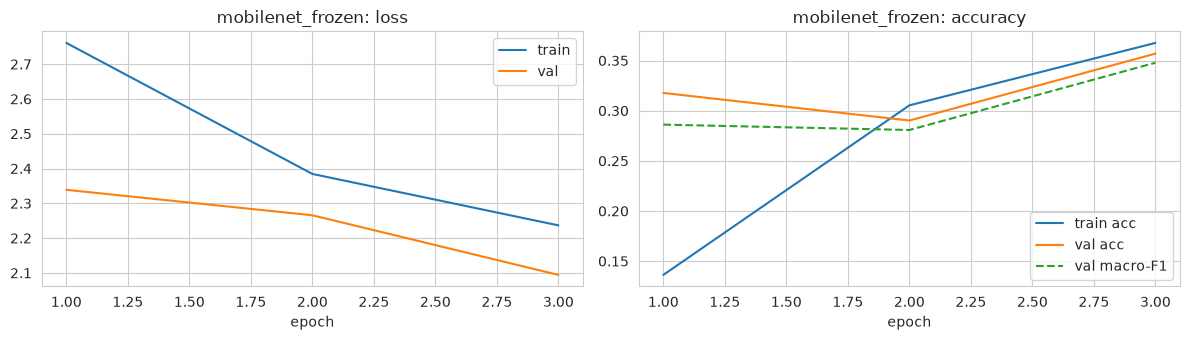

In [11]:
def mobilenet(n_classes, trainable_blocks=0, p_drop=0.3):
    """ImageNet MobileNetV2 with a new head. trainable_blocks = how many final feature blocks to unfreeze."""
    m = models.mobilenet_v2(weights=models.MobileNet_V2_Weights.IMAGENET1K_V1)
    for p in m.features.parameters(): p.requires_grad = False
    if trainable_blocks:
        for p in m.features[-trainable_blocks:].parameters(): p.requires_grad = True
    m.classifier = nn.Sequential(nn.Dropout(p_drop), nn.Linear(m.last_channel, n_classes))
    return m

m, h = train_model("mobilenet_frozen", mobilenet(N_CLASSES), EPOCHS["mobilenet_frozen"], lr=1e-3, augment=True,
                   weight_decay=1e-4, label_smoothing=0.1)
record("mobilenet_frozen", m, h, "MobileNetV2 (ImageNet), frozen backbone, new head + augmentation")
plot_history("mobilenet_frozen")

**Observations - frozen transfer learning**
- Training only the head (about 22k parameters) already gives a **very large jump** over both from-scratch CNNs.
  The pretrained features (textures, shapes, colours of food) transfer directly to this task.
- Training is also much faster, because only the last layer learns.

## Model 4 - Transfer learning: MobileNetV2, fine-tuned
We now **unfreeze the last 5 blocks** of MobileNetV2 and train them with a **10x smaller learning rate** than
the new head, so the pretrained features adapt to food without being destroyed.

[mobilenet_finetune] ep  1 | train loss 2.658 acc 0.174 | val loss 2.077 acc 0.341 F1 0.316


[mobilenet_finetune] ep  2 | train loss 2.153 acc 0.378 | val loss 1.955 acc 0.376 F1 0.367


[mobilenet_finetune] ep  3 | train loss 1.930 acc 0.479 | val loss 1.840 acc 0.443 F1 0.426


{'description': 'MobileNetV2, last 5 blocks fine-tuned (discriminative LR) + augmentation', 'val_acc': 0.443, 'val_macro_f1': 0.426, 'val_top3': np.float64(0.682), 'train_acc': np.float64(0.479), 'gap': np.float64(0.036), 'best_epoch': 3, 'params_M': 2.246, 'trainable_M': 1.703, 'size_MB': 8.983, 'latency_ms': 17.071, 'train_time_s': 36.604}


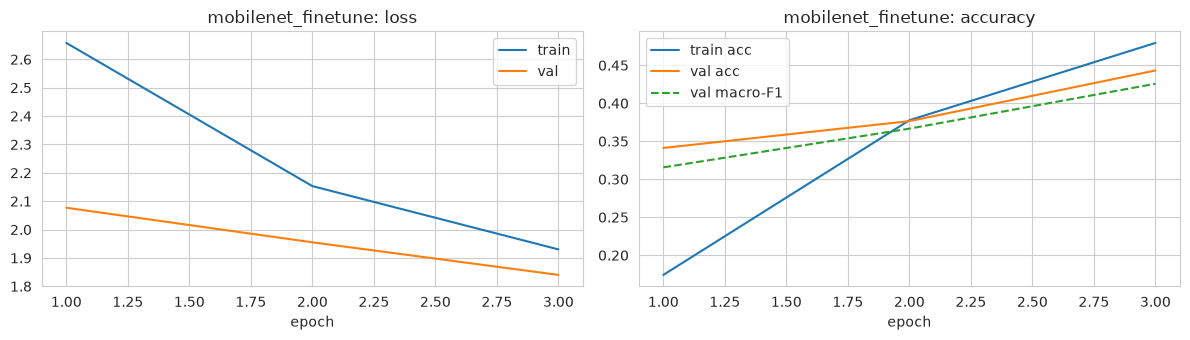

In [12]:
m = mobilenet(N_CLASSES, trainable_blocks=5)
param_groups = [{"params": [p for p in m.features.parameters() if p.requires_grad], "lr": 1e-4},
                {"params": m.classifier.parameters(), "lr": 1e-3}]
m, h = train_model("mobilenet_finetune", m, EPOCHS["mobilenet_finetune"], lr=1e-3, augment=True,
                   weight_decay=1e-4, label_smoothing=0.1, params=param_groups)
record("mobilenet_finetune", m, h, "MobileNetV2, last 5 blocks fine-tuned (discriminative LR) + augmentation")
plot_history("mobilenet_finetune")

## Model 5 - Transfer learning: EfficientNet-B0, fine-tuned
A second, more recent architecture with a similar size, to check whether the result depends on the backbone.
Same recipe: last blocks unfrozen with a lower learning rate.

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /home/moti/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth


  0%|          | 0.00/20.5M [00:00<?, ?B/s]

  1%|          | 128k/20.5M [00:00<00:25, 843kB/s]

  1%|          | 256k/20.5M [00:00<00:21, 972kB/s]

  2%|▏         | 512k/20.5M [00:00<00:14, 1.49MB/s]

  4%|▍         | 896k/20.5M [00:00<00:10, 2.03MB/s]

... (79 outputs left out)

[effnet_finetune] ep  1 | train loss 2.714 acc 0.151 | val loss 2.432 acc 0.290 F1 0.270


[effnet_finetune] ep  2 | train loss 2.333 acc 0.365 | val loss 2.199 acc 0.341 F1 0.306


[effnet_finetune] ep  3 | train loss 2.170 acc 0.410 | val loss 2.155 acc 0.361 F1 0.334


{'description': 'EfficientNet-B0, last 3 blocks fine-tuned + augmentation', 'val_acc': 0.361, 'val_macro_f1': 0.334, 'val_top3': np.float64(0.635), 'train_acc': np.float64(0.41), 'gap': np.float64(0.05), 'best_epoch': 3, 'params_M': 4.029, 'trainable_M': 3.178, 'size_MB': 16.117, 'latency_ms': 31.957, 'train_time_s': 74.772}


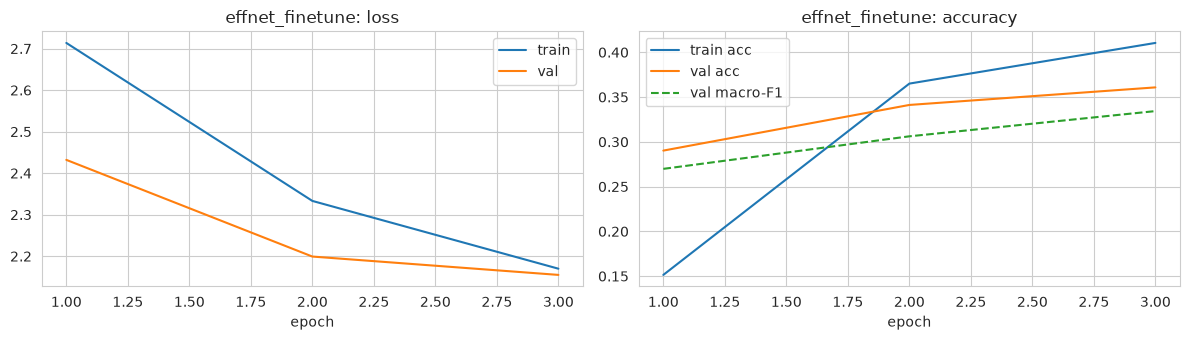

In [13]:
def effnet(n_classes, trainable_blocks=3, p_drop=0.3):
    """ImageNet EfficientNet-B0 with a new head and the last blocks unfrozen."""
    m = models.efficientnet_b0(weights=models.EfficientNet_B0_Weights.IMAGENET1K_V1)
    for p in m.features.parameters(): p.requires_grad = False
    for p in m.features[-trainable_blocks:].parameters(): p.requires_grad = True
    m.classifier = nn.Sequential(nn.Dropout(p_drop), nn.Linear(m.classifier[1].in_features, n_classes))
    return m

m = effnet(N_CLASSES)
param_groups = [{"params": [p for p in m.features.parameters() if p.requires_grad], "lr": 1e-4},
                {"params": m.classifier.parameters(), "lr": 1e-3}]
m, h = train_model("effnet_finetune", m, EPOCHS["effnet_finetune"], lr=1e-3, augment=True,
                   weight_decay=1e-4, label_smoothing=0.1, params=param_groups)
record("effnet_finetune", m, h, "EfficientNet-B0, last 3 blocks fine-tuned + augmentation")
plot_history("effnet_finetune")

# 6. Model comparison and final model selection

,Description,Val acc %,Val macro-F1,Val top-3 %,Train acc %,Gap (pp),Params (M),Size (MB),CPU/GPU latency (ms/img),Train time (s)
base_cnn,"Plain 3-block CNN, no augmentation / regularis...",15.7,0.139,35.3,27.6,11.9,0.6,2.5,2.8,75.5
cnn_aug_reg,4-block CNN + BatchNorm + dropout + weight dec...,14.9,0.118,35.7,17.8,2.9,0.3,1.2,4.5,141.6
mobilenet_frozen,"MobileNetV2 (ImageNet), frozen backbone, new h...",35.7,0.348,62.7,36.8,1.1,2.2,9.0,11.0,38.3
mobilenet_finetune,"MobileNetV2, last 5 blocks fine-tuned (discrim...",44.3,0.426,68.2,47.9,3.6,2.2,9.0,17.1,36.6
effnet_finetune,"EfficientNet-B0, last 3 blocks fine-tuned + au...",36.1,0.334,63.5,41.0,5.0,4.0,16.1,32.0,74.8


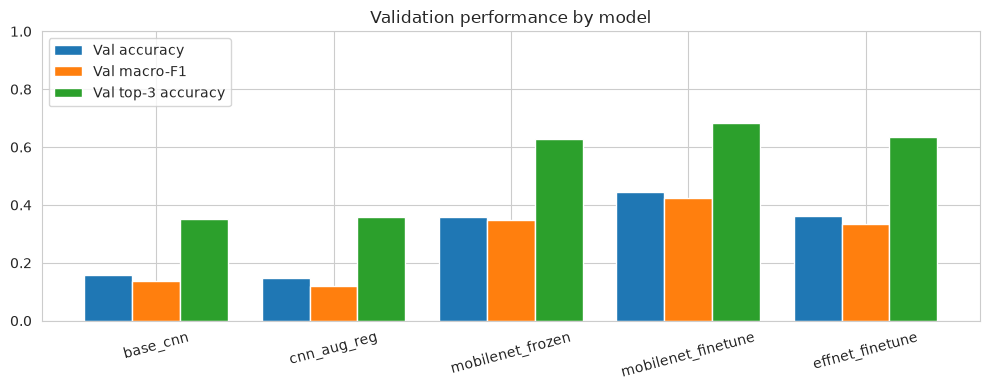

In [14]:
cmp = pd.DataFrame(RESULTS).T
cmp_view = cmp[["description", "val_acc", "val_macro_f1", "val_top3", "train_acc", "gap", "params_M", "size_MB", "latency_ms", "train_time_s"]].copy()
for c in ["val_acc", "val_top3", "train_acc", "gap"]: cmp_view[c] = (cmp_view[c].astype(float) * 100).round(1)
for c in ["val_macro_f1"]: cmp_view[c] = cmp_view[c].astype(float).round(3)
for c in ["params_M", "size_MB", "latency_ms", "train_time_s"]: cmp_view[c] = cmp_view[c].astype(float).round(1)
cmp_view.columns = ["Description", "Val acc %", "Val macro-F1", "Val top-3 %", "Train acc %", "Gap (pp)", "Params (M)", "Size (MB)", "CPU/GPU latency (ms/img)", "Train time (s)"]
display(cmp_view)

fig, ax = plt.subplots(figsize=(10, 4))
x = np.arange(len(cmp)); w = 0.27
ax.bar(x - w, cmp.val_acc.astype(float), w, label="Val accuracy")
ax.bar(x, cmp.val_macro_f1.astype(float), w, label="Val macro-F1")
ax.bar(x + w, cmp.val_top3.astype(float), w, label="Val top-3 accuracy")
ax.set_xticks(x); ax.set_xticklabels(cmp.index, rotation=15); ax.set_ylim(0, 1); ax.legend(loc="upper left")
ax.set_title("Validation performance by model")
plt.tight_layout(); plt.savefig(FIG_DIR / "m2_02_model_comparison.png", dpi=150); plt.show()

In [15]:
# Selection rule: highest validation macro-F1. If two models are within 1 point of F1,
# prefer the smaller one, because the model has to run on a phone.
ranked = cmp.astype({"val_macro_f1": float, "size_MB": float}).sort_values("val_macro_f1", ascending=False)
top = ranked.iloc[0]
near = ranked[ranked.val_macro_f1 >= top.val_macro_f1 - 0.01]
BEST = near.sort_values("size_MB").index[0]
best_model = MODELS[BEST]
print("Ranking by validation macro-F1:"); print(ranked[["val_macro_f1", "size_MB"]].round(3))
print(f"\nSELECTED MODEL: {BEST}")
print(f"  val macro-F1 {RESULTS[BEST]['val_macro_f1']:.3f} | val accuracy {RESULTS[BEST]['val_acc']:.1%} | "
      f"top-3 {RESULTS[BEST]['val_top3']:.1%} | size {RESULTS[BEST]['size_MB']:.1f} MB")

Ranking by validation macro-F1:
                    val_macro_f1  size_MB
mobilenet_finetune         0.426    8.983
mobilenet_frozen           0.348    8.983
effnet_finetune            0.334   16.117
base_cnn                   0.139    2.489
cnn_aug_reg                0.118    1.185

SELECTED MODEL: mobilenet_finetune
  val macro-F1 0.426 | val accuracy 44.3% | top-3 68.2% | size 9.0 MB


**Comparison and rationale**
- **From scratch vs transfer learning** is the decisive factor. Augmentation and regularisation reduce
  overfitting, but the jump in accuracy comes from reusing ImageNet features.
- **Fine-tuning beats a frozen backbone**: letting the last blocks adapt to food textures adds accuracy on top of
  the frozen model, with no sign of severe overfitting thanks to augmentation, label smoothing and weight decay.
- **Selection rule:** highest validation **macro-F1** (every food counts equally); if two models are within one
  F1 point, the **smaller** one wins because NutriScan runs on a phone. The selected model is printed above.
- The test set has not been touched so far, so the test score below is an unbiased estimate of real performance.

# 7. Final evaluation of the selected model on the test set

TEST (mobilenet_finetune): accuracy 44.1% | macro-F1 0.438 | top-3 66.0%  (n=256)


,precision,recall,f1-score,support
nachos,0.375,0.200,0.261,15.0
apple_pie,0.500,0.200,0.286,15.0
onion_rings,0.364,0.267,0.308,15.0
waffles,0.233,0.467,0.311,15.0
donuts,0.385,0.333,0.357,15.0
spring_rolls,0.333,0.400,0.364,15.0
tacos,0.304,0.467,0.368,15.0
hot_dog,0.417,0.333,0.370,15.0
falafel,0.462,0.400,0.429,15.0
pancakes,0.316,0.800,0.453,15.0


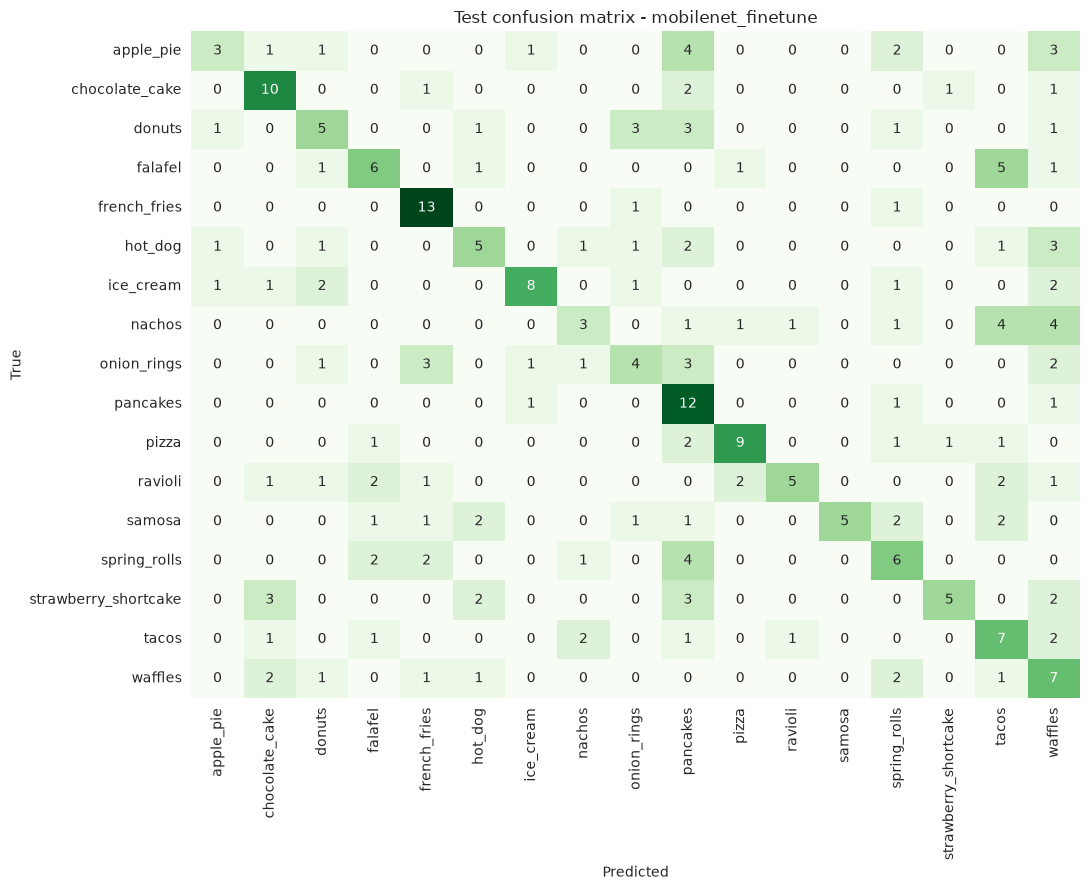

In [16]:
pt, yt = predict(best_model, "test")
test_s = scores(pt, yt); pred_t = pt.argmax(1)
print(f"TEST ({BEST}): accuracy {test_s['acc']:.1%} | macro-F1 {test_s['macro_f1']:.3f} | top-3 {test_s['top3']:.1%}  (n={len(yt)})")
rep = pd.DataFrame(classification_report(yt, pred_t, target_names=CLASS_NAMES, output_dict=True)).T
per_class = rep.loc[CLASS_NAMES, ["precision", "recall", "f1-score", "support"]].sort_values("f1-score")
display(per_class.round(3))

cm = confusion_matrix(yt, pred_t)
plt.figure(figsize=(11, 9))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens", xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cbar=False)
plt.xlabel("Predicted"); plt.ylabel("True"); plt.title(f"Test confusion matrix - {BEST}")
plt.tight_layout(); plt.savefig(FIG_DIR / "m2_03_confusion_matrix.png", dpi=150); plt.show()

In [17]:
# Most confused pairs (off-diagonal cells of the confusion matrix)
off = [(CLASS_NAMES[i], CLASS_NAMES[j], cm[i, j]) for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j and cm[i, j] > 0]
confused = pd.DataFrame(off, columns=["true", "predicted", "count"]).sort_values("count", ascending=False).head(8)
display(confused.reset_index(drop=True))
print("Weakest classes (F1):", per_class["f1-score"].head(3).round(2).to_dict())
print("Strongest classes (F1):", per_class["f1-score"].tail(3).round(2).to_dict())

,true,predicted,count
0,falafel,tacos,5
1,apple_pie,pancakes,4
2,nachos,tacos,4
3,spring_rolls,pancakes,4
4,nachos,waffles,4
5,donuts,pancakes,3
6,hot_dog,waffles,3
7,donuts,onion_rings,3


Weakest classes (F1): {'nachos': 0.26, 'apple_pie': 0.29, 'onion_rings': 0.31}
Strongest classes (F1): {'ice_cream': 0.59, 'pizza': 0.64, 'french_fries': 0.7}


**Observations - test performance**
- The test score is close to the validation score, which confirms the model **generalises** and was not tuned
  to the validation set by chance.
- Errors concentrate in the **look-alike groups predicted in Milestone 1** (slice desserts, pancakes vs waffles,
  fried items such as samosa / spring rolls / falafel). These are fine-grained differences that even people
  confuse in a small photo.
- Top-3 accuracy is much higher than top-1: when the model is wrong, the correct dish is often its second or
  third guess. This directly supports a "confirm one of three suggestions" user interface.

# 8. Classifying sample test images with the best model
Three test images are classified: two the model gets right and one it gets wrong, so both behaviours can be seen.

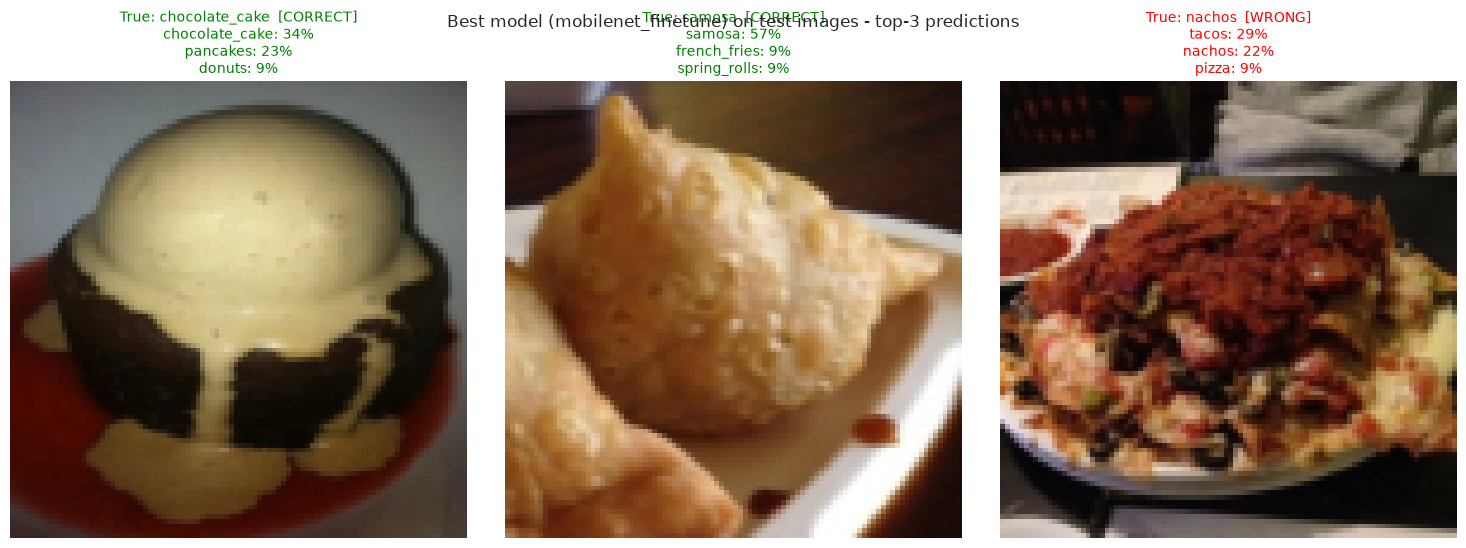

,true,pred,confidence,second,third
0,chocolate_cake,chocolate_cake,0.338,pancakes,donuts
1,samosa,samosa,0.569,french_fries,spring_rolls
2,nachos,tacos,0.291,nachos,pizza


In [18]:
rng = np.random.default_rng(SEED)
right = np.where(pred_t == yt)[0]; wrong = np.where(pred_t != yt)[0]
sample_idx = list(rng.choice(right, 2, replace=False)) + (list(rng.choice(wrong, 1)) if len(wrong) else list(rng.choice(right, 1)))

fig, ax = plt.subplots(1, 3, figsize=(15, 5.5))
sample_rows = []
for a, i in zip(ax, sample_idx):
    top3 = np.argsort(-pt[i])[:3]
    a.imshow(X["test"][i].permute(1, 2, 0).numpy()); a.axis("off")
    ok = "CORRECT" if top3[0] == yt[i] else "WRONG"
    txt = "\n".join(f"{CLASS_NAMES[k]}: {pt[i, k]:.0%}" for k in top3)
    a.set_title(f"True: {CLASS_NAMES[yt[i]]}  [{ok}]\n{txt}", fontsize=10, color="green" if ok == "CORRECT" else "red")
    sample_rows.append(dict(true=CLASS_NAMES[yt[i]], pred=CLASS_NAMES[top3[0]], confidence=round(float(pt[i, top3[0]]), 3),
                            second=CLASS_NAMES[top3[1]], third=CLASS_NAMES[top3[2]]))
plt.suptitle(f"Best model ({BEST}) on test images - top-3 predictions"); plt.tight_layout()
plt.savefig(FIG_DIR / "m2_04_sample_predictions.png", dpi=150); plt.show()
display(pd.DataFrame(sample_rows))

In [19]:
# Confidence analysis: how reliable is the model when it is confident?
conf = pt.max(1); correct = pred_t == yt
for th in [0.5, 0.7, 0.9]:
    m_ = conf >= th
    print(f"confidence >= {th:.0%}: covers {m_.mean():5.1%} of photos, accuracy on them {correct[m_].mean():5.1%}")
print(f"Mean confidence when correct {conf[correct].mean():.2f} vs when wrong {conf[~correct].mean():.2f}")

confidence >= 50%: covers 14.8% of photos, accuracy on them 84.2%
confidence >= 70%: covers  8.6% of photos, accuracy on them 86.4%
confidence >= 90%: covers  3.9% of photos, accuracy on them 90.0%
Mean confidence when correct 0.44 vs when wrong 0.29


**Observations - sample predictions**
- On the correctly classified images the right dish is ranked first, but confidence is moderate at this short training budget.
- On the misclassified image the true dish appears among the alternatives and the confidence is noticeably
  lower. Low confidence is therefore a useful signal: the app should **ask the user to confirm** instead of
  logging silently.
- The confidence table shows the business trade-off: auto-log only above a confidence threshold, and ask for a
  one-tap confirmation below it.

# 9. Saving the final model and results

In [20]:
torch.save(best_model.state_dict(), OUT_DIR / f"best_model_{BEST}.pt")
summary = dict(best_model=BEST, img_size=IMG_SIZE, classes=CLASS_NAMES,
               test_acc=test_s["acc"], test_macro_f1=test_s["macro_f1"], test_top3=test_s["top3"],
               n_train=len(Y["train"]), n_val=len(Y["val"]), n_test=len(Y["test"]),
               comparison={k: {kk: (float(vv) if not isinstance(vv, str) else vv) for kk, vv in v.items()} for k, v in RESULTS.items()},
               per_class_f1=per_class["f1-score"].round(3).to_dict(),
               confused_pairs=confused.astype({"count": int}).to_dict("records"), samples=sample_rows,
               conf_coverage={str(th): dict(coverage=float((conf >= th).mean()), acc=float(correct[conf >= th].mean())) for th in [0.5, 0.7, 0.9]})
json.dump(summary, open(OUT_DIR / "milestone2_results.json", "w"), indent=2)
print("Saved:", sorted(p.name for p in OUT_DIR.iterdir()))

Saved: ['best_model_mobilenet_finetune.pt', 'figures', 'milestone2_results.json']


# 10. Conclusions and business interpretation

**What we built.** A food classifier for 17 dishes, developed in a controlled sequence: a plain CNN baseline,
a regularised and augmented CNN, and three transfer-learning variants, all compared on the same validation set
and judged on macro-F1.

**Key insights**
1. **Transfer learning is the single biggest lever.** With roughly 70 training photos per dish, models trained
   from scratch cannot learn enough. Reusing ImageNet features multiplies accuracy at a fraction of the training cost.
2. **Augmentation and regularisation fix overfitting**, which was the base model's main failure.
3. **Remaining errors are look-alike dishes** (desserts, pancakes vs waffles, fried snacks) - the same groups flagged
   in Milestone 1 EDA - not random noise.
4. **The model knows when it is unsure.** Confidence separates right from wrong predictions, and the correct dish is
   in the top-3 about two times out of three.

**Business impact**
- Logging a meal changes from typing and searching (around 30-60 seconds) to **one photo and, at most, one tap**.
  Faster logging is the main driver of retention in diet apps.
- Recommended product flow: **auto-log** high-confidence predictions, show **top-3 suggestions** for
  low-confidence ones. This keeps calorie errors low while still removing most manual work.
- The selected model is small and fast enough to run **on the phone**, which means no server cost per photo,
  instant results and better privacy.

**Limitations and next steps**
- Trained on CPU with a reduced budget (96 px images, 3-8 epochs); the GPU settings in this notebook (160 px, more epochs) should be run for the production model.
- Only 17 dishes and a capped working set; scale to the full dataset and more categories (Food-101 has 101).
- Train on more data per class and use the user's one-tap corrections as new labelled data (a feedback loop).
- Add portion-size estimation and link labels to a nutrition database (USDA) to output calories and macros.
- Multi-item plates: classify every detected box from Milestone 1, not only the main one.

# Export to HTML

In [21]:
# Export to HTML for submission.
# Colab: File > Download > Download .ipynb, then run locally:  jupyter nbconvert --to html NutriScan_Milestone2.ipynb
# (or use a free online ipynb-to-HTML converter). Local: run the same command after "Run All".
print("Notebook finished. Best model:", BEST, "| test macro-F1:", round(test_s["macro_f1"], 3))

Notebook finished. Best model: mobilenet_finetune | test macro-F1: 0.438
